# 📏 베이스라인 평가 — 정확도의 함정 확인

- **목적**: 아무것도 학습하지 않는 Dummy 모델과 기본 로지스틱 회귀로, 이후 모델이 넘어야 할 **기준선**을 정합니다.
- **선행**: `eda_and_split.ipynb`
- **산출물**: `reports/tables/baseline_val_metrics.csv`, `baseline_val_thresholds.csv`, `reports/figures/logistic_regression_simulation.png`
- **원칙**: Validation만 사용하며 Test 데이터는 사용하지 않습니다.

## 1. 환경 설정 및 데이터 로드

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# 프로젝트 최상위 폴더 (이 노트북은 experiments 폴더에서 실행)
PROJECT_ROOT = Path.cwd().parent

# 공통 함수가 있는 src 폴더를 파이썬 검색 경로에 추가 (한글 폰트도 utils에서 설정됨)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from utils import (
    load_and_preprocess_data,
    evaluate_fds_model,
    evaluate_thresholds,
    plot_and_save_simulation,
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"          # 결과표(CSV) 저장 위치
TABLE_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

X_train, y_train, X_val, y_val = load_and_preprocess_data(DATA_DIR)
print(f"검증 사기 거래: {y_val.sum()}건 ({y_val.mean():.4%})")

[Data Loaded] Train: (198621, 30), Validation: (42562, 30)
검증 사기 거래: 74건 (0.1739%)


## 2. Baseline 1 — Dummy 모델 (정확도의 함정)

모든 거래를 "정상"으로 예측합니다. 정확도는 99.8%를 넘지만 사기는 한 건도 잡지 못합니다.
사기 확률은 모든 거래에 같은 값(학습 데이터의 사기 비율)을 주므로 PR-AUC는 무작위 수준(≈ 사기 비율)이 됩니다.

In [2]:
results = []

# 가장 많은 클래스(0: 정상)로만 예측하는 모델
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_val)
# 모든 거래에 같은 사기 확률(학습 데이터 사기 비율)을 부여
dummy_prob = np.full(len(y_val), y_train.mean(), dtype=float)

results.append(evaluate_fds_model("Dummy Model (Most Frequent)", y_val, dummy_pred, dummy_prob))


================ [Dummy Model (Most Frequent)] 평가 결과 ================
1. Accuracy  (정확도) : 0.99826
2. PR-AUC    (평균정밀도): 0.00174 ★
3. Recall    (재현율)  : 0.00000
4. Precision (정밀도)  : 0.00000
5. F1-Score  (조화평균): 0.00000
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42488     0]
 [   74     0]]
 - TN(정상 예측 성공): 42,488건 | FP(오탐 / 오인 신고): 0건 | FN(미탐 / 놓친 사기): 74건 | TP(사기 탐지 성공): 0건



## 3. Baseline 2 — 기본 로지스틱 회귀

클래스 가중치나 임계값 조정 없이 기본 설정(임계값 0.5)으로 학습한 선형 모델입니다.

In [3]:
lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, solver="lbfgs")
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_val)                 # 기본 임계값 0.5 기준 예측
lr_prob = lr_model.predict_proba(X_val)[:, 1]     # 사기(1) 클래스 확률

results.append(evaluate_fds_model("Basic Logistic Regression", y_val, lr_pred, lr_prob))


================ [Basic Logistic Regression] 평가 결과 ================
1. Accuracy  (정확도) : 0.99901
2. PR-AUC    (평균정밀도): 0.66543 ★
3. Recall    (재현율)  : 0.55405
4. Precision (정밀도)  : 0.82000
5. F1-Score  (조화평균): 0.66129
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42479     9]
 [   33    41]]
 - TN(정상 예측 성공): 42,479건 | FP(오탐 / 오인 신고): 9건 | FN(미탐 / 놓친 사기): 33건 | TP(사기 탐지 성공): 41건



## 4. 로지스틱 회귀 임계값별 검토 건수 시뮬레이션

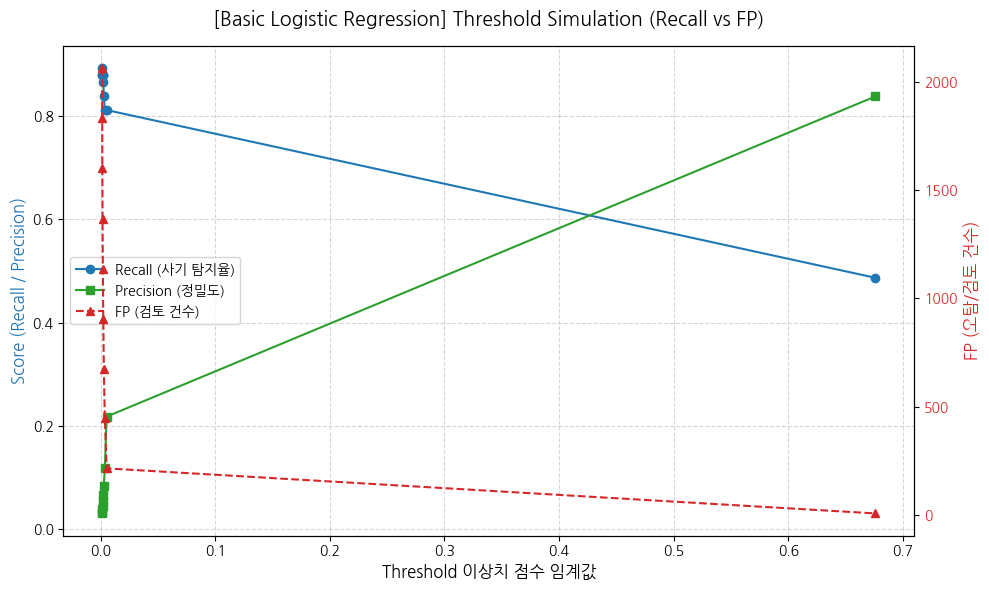

[저장 완료] 그래프 파일: /home/user1/study/credit-card-fds/reports/figures/logistic_regression_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.001359,0.891892,0.031000,0.059918,66,2063,8,2129,LogisticRegression,validation
1,0.001474,0.878378,0.034265,0.065956,65,1832,9,1897,LogisticRegression,validation
2,0.001616,0.878378,0.039039,0.074756,65,1600,9,1665,LogisticRegression,validation
3,0.001785,0.878378,0.045359,0.086264,65,1368,9,1433,LogisticRegression,validation
4,0.002034,0.878378,0.054077,0.101881,65,1137,9,1202,LogisticRegression,validation
5,0.002408,0.864865,0.065979,0.122605,64,906,10,970,LogisticRegression,validation
6,0.002881,0.837838,0.084011,0.152709,62,676,12,738,LogisticRegression,validation
7,0.003747,0.810811,0.118343,0.206540,60,447,14,507,LogisticRegression,validation
8,0.005355,0.810811,0.218182,0.343840,60,215,14,275,LogisticRegression,validation
9,0.676032,0.486486,0.837209,0.615385,36,7,38,43,LogisticRegression,validation


In [4]:
# 임계값 후보를 지정하지 않으면 확률 상위 0.1~5% 구간에서 10개를 자동 생성
lr_thresholds = evaluate_thresholds(y_val, lr_prob)
lr_thresholds["Model"] = "LogisticRegression"
lr_thresholds["Split"] = "validation"

# 그래프의 오른쪽 축은 총 검토 건수가 아닌 FP(오탐 건수)
plot_and_save_simulation(
    lr_thresholds,
    model_name="Basic Logistic Regression",
    filename="logistic_regression_simulation.png",
    figures_dir=FIGURE_DIR,
)
display(lr_thresholds)

## 5. 결과 저장 및 요약

In [5]:
results_df = pd.DataFrame(results)
results_df["Split"] = "validation"
results_df["Threshold"] = 0.5

results_df.to_csv(TABLE_DIR / "baseline_val_metrics.csv", index=False, encoding="utf-8-sig")
lr_thresholds.to_csv(TABLE_DIR / "baseline_val_thresholds.csv", index=False, encoding="utf-8-sig")
print(f"[저장] {TABLE_DIR / 'baseline_val_metrics.csv'}")
print(f"[저장] {TABLE_DIR / 'baseline_val_thresholds.csv'}")

display(results_df[["Model", "Accuracy", "PR_AUC", "Recall", "Precision", "TP", "FP", "FN"]].round(4))

[저장] /home/user1/study/credit-card-fds/reports/tables/baseline_val_metrics.csv
[저장] /home/user1/study/credit-card-fds/reports/tables/baseline_val_thresholds.csv


,Model,Accuracy,PR_AUC,Recall,Precision,TP,FP,FN
0,Dummy Model (Most Frequent),0.9983,0.0017,0.0000,0.00,0,0,74
1,Basic Logistic Regression,0.9990,0.6654,0.5541,0.82,41,9,33
